-Martina Yed- Análisis y Procesamiento de Señales

TS4: Primeras nociones de estimación espectral

Lo nuevo que incorporamos en este informe a diferencias de las ts semanalas pasadas, es el diseño de estimadores para calcular la amplitud y la frecuencia de una señal, además de analizar cómo se comportan frente al ruido.Para la experimentación, partimos de una señal $$x(k) = a_0 \cdot \sin(\Omega_1 \cdot n) + n_a(n)$$ compuesta por una senoidal a la que se le suma ruido gaussiano.Donde la frecuencia $\Omega_1$ tiene una componente aleatoria uniforme, y $n_a \sim N(0, \sigma^2)$ es el ruido aditivo gaussiano. Para comparar los métodos en igualdad de condiciones, la amplitud se calibra para que la potencia de la senoidal sea siempre de 1 W bajo relaciones señal-ruido (SNR) de 3 y 10 dB.
Sobre esta señal, implementamos dos estimadores. Un estimador es, básicamente, una función o regla matemática que aplicamos a nuestras muestras para deducir el valor de un parámetro desconocido. Buscamos estimar dos cosas:
**Estimador de Amplitud ($\hat{a}_{i1}$):** Lo calculamos buscando el valor absoluto de la transformada de Fourier de la señal multiplicada por una ventana $w_i(n)$.
**Estimador de Frecuencia ($\hat{\Omega}_{i1}$):** Buscamos en qué frecuencia se da el pico máximo de la magnitud de la transformada.

Como estamos trabajando con variables aleatorias (por el ruido y la frecuencia variable de la señal original), cada vez que corremos el codigo el resultado cambia un poco. Por eso, para evaluar qué tan precisos son nuestros estimadores al usar distintas ventanas (como Rectangular, Flat-top, Blackman-Harris), usamos dos conceptos estadísticos fundamentales que nos permiten medir el error: el sesgo y la varianza.
**Sesgo:** El sesgo es la diferencia entre el valor esperado (la media) de nuestra estimación y el valor "verdadero" de la cantidad que estamos intentando estimar. En nuestro experimento, lo aproximamos restando el valor real de la amplitud ($a_0$) a la media de las amplitudes que fuimos estimando ($\mu_{\hat{a}}$), resultando en la fórmula $s_a = \mu_{\hat{a}} - a_0$. Básicamente, si el sesgo es cero o muy chico, significa que nuestro estimador le "apunta" correctamente al valor real en promedio. Igual algo importante que mas adelante lo cuento mejor pero es importante saber que el sesgo se puede corregir por asi decirlo.  
**Varianza:** La varianza nos indica qué tan dispersas están las distintas estimaciones repetidas del proceso alrededor de la media muestral. Lo calculamos midiendo qué tanto se aleja cada estimación individual del promedio total elevado al cuadrado, con la fórmula $v_a = \frac{1}{M} \sum_{j=0}^{M-1} (\hat{a}_j - \mu_{\hat{a}})^2$. Un estimador se considera consistente si su varianza se acerca a cero, lo que significa que la dispersión de las estimaciones repetidas disminuye. En otras palabras, una varianza chica nos asegura que los resultados de nuestro código son estables y no varían bruscamente en cada realización.
Idealmente, un buen estimador tendría que tener poca varianza y poco sesgo, pero como eso es muy difícil, siempre terminamos sacrificando una cosa por la otra. Lo importante acá es entender que suele convenir tener poca varianza aunque haya mucho sesgo, total el sesgo es algo que después podemos llegar a compensar o corregir. También hay que tener siempre en cuenta cómo se relacionan: por lo general, si tenés muy poco de uno, vas a tener mucho del otro. 
Además, implementamos el tema de las ventanas. Hay diferentes tipos de ventanas, cada una con sus características, y que nos sirven para cosas diferentes dependiendo de lo que queramos.

---SNR 10dB----

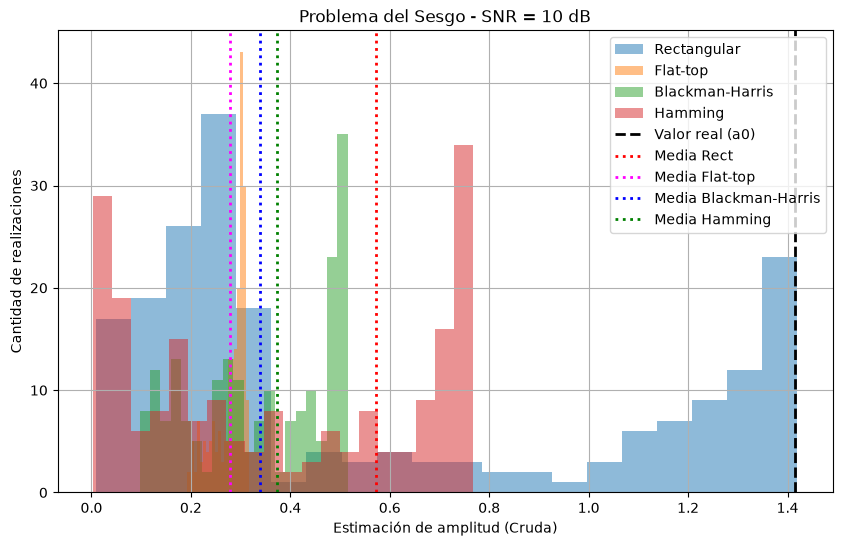

In [2]:
# -*- coding: utf-8 -*-

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# PARÁMETROS
N = 1000              
M = 200               
a0 = np.sqrt(2)       
Omega0 = np.pi / 2    
n = np.arange(N)
SNR_dB = 10          
fs = 1000

# RUIDO SEGÚN SNR
Ps = 1
Pn = Ps / (10**(SNR_dB / 10))
sigma = np.sqrt(Pn)

# GENERACIÓN (Usamos seed para que ambos bloques usen la misma señal si se corren separados)
np.random.seed(42)
x = np.zeros((M, N))
Omega1 = np.zeros(M)
for i in range(M):
    fr = np.random.uniform(-2, 2)
    Omega1[i] = Omega0 + fr * (2*np.pi/N)
    na = np.random.normal(0, sigma, N)
    x[i, :] = a0 * np.sin(Omega1[i] * n) + na

# VENTANAS Y FFT
w_rect = signal.windows.boxcar(N)
w_flattop = signal.windows.flattop(N)
w_blackmanharris = signal.windows.blackmanharris(N)
w_hamming = signal.windows.hamming(N)

mod_a_rect = np.abs(np.fft.fft(x * w_rect, axis=1)[:, :N//2])
mod_a_flat = np.abs(np.fft.fft(x * w_flattop, axis=1)[:, :N//2])
mod_a_black = np.abs(np.fft.fft(x * w_blackmanharris, axis=1)[:, :N//2])
mod_a_ham = np.abs(np.fft.fft(x * w_hamming, axis=1)[:, :N//2])

# EXTRACCIÓN CRUDA 
k0 = N // 4
est_a_rect = mod_a_rect[:, k0] * (2 / N)
est_a_flat = mod_a_flat[:, k0] * (2 / N)
est_a_black = mod_a_black[:, k0] * (2 / N)
est_a_ham = mod_a_ham[:, k0] * (2 / N)

# CÁLCULO DE MEDIAS
media_rect = np.mean(est_a_rect)
media_flat = np.mean(est_a_flat)
media_black = np.mean(est_a_black)
media_ham = np.mean(est_a_ham)

# GRAFICO
plt.figure(figsize=(10, 6))
plt.hist(est_a_rect, bins=20, alpha=0.5, label='Rectangular')
plt.hist(est_a_flat, bins=20, alpha=0.5, label='Flat-top')
plt.hist(est_a_black, bins=20, alpha=0.5, label='Blackman-Harris')
plt.hist(est_a_ham, bins=20, alpha=0.5, label='Hamming')

# LÍNEAS DE REFERENCIA
plt.axvline(a0, color='black', linestyle='--', linewidth=2, label='Valor real (a0)')
plt.axvline(media_rect, color='red', linestyle=':', linewidth=2, label='Media Rect')
plt.axvline(media_flat, color='magenta', linestyle=':', linewidth=2, label='Media Flat-top')
plt.axvline(media_black, color='blue', linestyle=':', linewidth=2, label='Media Blackman-Harris')
plt.axvline(media_ham, color='green', linestyle=':', linewidth=2, label='Media Hamming')

plt.xlabel('Estimación de amplitud (Cruda)')
plt.ylabel('Cantidad de realizaciones')
plt.title(f'Problema del Sesgo - SNR = {SNR_dB} dB')
plt.legend()
plt.grid()
plt.show()

Acá vemos el histograma de amplitudes, donde cada color representa una ventana distinta. Le agregué unas líneas punteadas para representar la media de cada una, así capaz resulta más visual ver el sesgo y la varianza (a mí por lo menos me sirvió un montón para entender y diferenciar bien los conceptos). A simple vista se nota que todas las ventanas tienen un sesgo enorme, ya que deberían estar centradas cerca de 1,41 por el valor de a0. Pero eso en este punto no nos importa tanto porque es un error que después vamos a corregir; lo que sí nos importa es ver cuál ventana tiene menos varianza. Para mi análisis, la mejor ventana acá es la Flat-top. Después con la tabla y los números se va a confirmar mejor, pero viéndolo gráficamente yo diría que la Flat-top es la que tiene menos varianza porque tiene mucho menos "desparramo". Es decir, podemos ver que sus estimaciones están mucho más centradas en una franja finita alrededor de su propia media, a diferencia de la ventana Rectangular, por ejemplo, que deja los valores dispersos por cualquier lado.

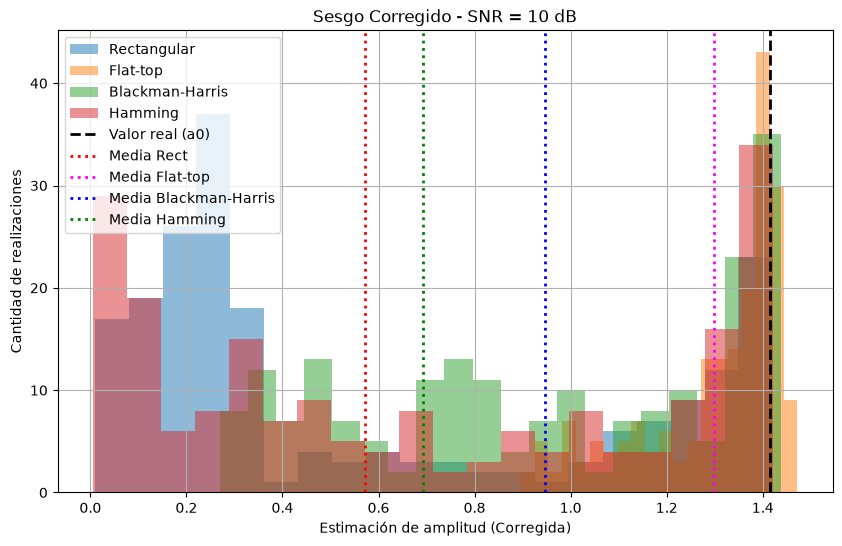

In [4]:
# -*- coding: utf-8 -*-

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# PARÁMETROS
N = 1000              
M = 200               
a0 = np.sqrt(2)       
Omega0 = np.pi / 2    
n = np.arange(N)
SNR_dB = 10          
fs = 1000

# RUIDO SEGÚN SNR
Ps = 1
Pn = Ps / (10**(SNR_dB / 10))
sigma = np.sqrt(Pn)

# GENERACIÓN (Misma semilla para mantener los mismos datos)
np.random.seed(42)
x = np.zeros((M, N))
Omega1 = np.zeros(M)
for i in range(M):
    fr = np.random.uniform(-2, 2)
    Omega1[i] = Omega0 + fr * (2*np.pi/N)
    na = np.random.normal(0, sigma, N)
    x[i, :] = a0 * np.sin(Omega1[i] * n) + na

# VENTANAS Y FFT
w_rect = signal.windows.boxcar(N)
w_flattop = signal.windows.flattop(N)
w_blackmanharris = signal.windows.blackmanharris(N)
w_hamming = signal.windows.hamming(N)

mod_a_rect = np.abs(np.fft.fft(x * w_rect, axis=1)[:, :N//2])
mod_a_flat = np.abs(np.fft.fft(x * w_flattop, axis=1)[:, :N//2])
mod_a_black = np.abs(np.fft.fft(x * w_blackmanharris, axis=1)[:, :N//2])
mod_a_ham = np.abs(np.fft.fft(x * w_hamming, axis=1)[:, :N//2])

# EXTRACCIÓN CORREGIDA (Usando la suma de cada ventana)
k0 = N // 4
est_a_rect = mod_a_rect[:, k0] * (2 / np.sum(w_rect))
est_a_flat = mod_a_flat[:, k0] * (2 / np.sum(w_flattop))
est_a_black = mod_a_black[:, k0] * (2 / np.sum(w_blackmanharris))
est_a_ham = mod_a_ham[:, k0] * (2 / np.sum(w_hamming))

# EXTRACCIÓN DE FRECUENCIA
paso_frec = 2 * np.pi / N
est_Omega_rect = np.argmax(mod_a_rect, axis=1) * paso_frec
est_Omega_flat = np.argmax(mod_a_flat, axis=1) * paso_frec
est_Omega_black = np.argmax(mod_a_black, axis=1) * paso_frec
est_Omega_ham = np.argmax(mod_a_ham, axis=1) * paso_frec

# CÁLCULOS ESTADÍSTICOS
media_rect, media_flat = np.mean(est_a_rect), np.mean(est_a_flat)
media_black, media_ham = np.mean(est_a_black), np.mean(est_a_ham)

sa_rect, va_rect = media_rect - a0, np.var(est_a_rect)
sa_flat, va_flat = media_flat - a0, np.var(est_a_flat)
sa_black, va_black = media_black - a0, np.var(est_a_black)
sa_ham, va_ham = media_ham - a0, np.var(est_a_ham)

sf_rect, vf_rect = np.mean(est_Omega_rect - Omega1), np.var(est_Omega_rect - Omega1)
sf_flat, vf_flat = np.mean(est_Omega_flat - Omega1), np.var(est_Omega_flat - Omega1)
sf_black, vf_black = np.mean(est_Omega_black - Omega1), np.var(est_Omega_black - Omega1)
sf_ham, vf_ham = np.mean(est_Omega_ham - Omega1), np.var(est_Omega_ham - Omega1)

# GRAFICO CORREGIDO
plt.figure(figsize=(10, 6))
plt.hist(est_a_rect, bins=20, alpha=0.5, label='Rectangular')
plt.hist(est_a_flat, bins=20, alpha=0.5, label='Flat-top')
plt.hist(est_a_black, bins=20, alpha=0.5, label='Blackman-Harris')
plt.hist(est_a_ham, bins=20, alpha=0.5, label='Hamming')

plt.axvline(a0, color='black', linestyle='--', linewidth=2, label='Valor real (a0)')
plt.axvline(media_rect, color='red', linestyle=':', linewidth=2, label='Media Rect')
plt.axvline(media_flat, color='magenta', linestyle=':', linewidth=2, label='Media Flat-top')
plt.axvline(media_black, color='blue', linestyle=':', linewidth=2, label='Media Blackman-Harris')
plt.axvline(media_ham, color='green', linestyle=':', linewidth=2, label='Media Hamming')

plt.xlabel('Estimación de amplitud (Corregida)')
plt.ylabel('Cantidad de realizaciones')
plt.title(f'Sesgo Corregido - SNR = {SNR_dB} dB')
plt.legend()
plt.grid()
plt.show()


Como acá ya compensamos matemáticamente el sesgo propio de la ventana, uno esperaría que ahora sí todas las medias (las líneas punteadas de colores) caigan justo sobre la línea negra gruesa del valor real (1,41).
La única que zafa casi por completo de este problema es justamente la Flat-top (naranja). Acá se re nota el porqué de su nombre (techo plano): está diseñada específicamente para que, aunque la frecuencia se corra un poquito del centro del bin, la amplitud que captura casi no disminuya. Por eso, su media (la línea punteada magenta) es la que logra quedar más pegada a la línea negra del valor real, manteniendo además esa varianza súper chiquita que ya le habíamos dicho en el gráfico crudo.
En cambio, las otras ventanas (como la Rectangular o la Hamming), por más que las hayamos corregido con la fórmula, siguen sufriendo un montón por ese corrimiento de frecuencia. Sus medias siguen quedando súper alejadas para atrás y mantienen un desparramo gigante. En resumen, si el primer gráfico nos sirvió para ver quién tenía menos varianza, este segundo gráfico nos sirve como prueba final para demostrar que la Flat-top es la única que logra darnos una estimación estable y centrada cuando la frecuencia no cae exacta en un bin.

In [5]:
# -*- coding: utf-8 -*-

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# PARÁMETROS
N = 1000              
M = 200               
a0 = np.sqrt(2)       
Omega0 = np.pi / 2    
n = np.arange(N)
SNR_dB = 10          
fs = 1000

# RUIDO SEGÚN SNR
Ps = 1
Pn = Ps / (10**(SNR_dB / 10))
sigma = np.sqrt(Pn)

# GENERACIÓN (Misma semilla para mantener los mismos datos)
np.random.seed(42)
x = np.zeros((M, N))
Omega1 = np.zeros(M)
for i in range(M):
    fr = np.random.uniform(-2, 2)
    Omega1[i] = Omega0 + fr * (2*np.pi/N)
    na = np.random.normal(0, sigma, N)
    x[i, :] = a0 * np.sin(Omega1[i] * n) + na

# VENTANAS Y FFT
w_rect = signal.windows.boxcar(N)
w_flattop = signal.windows.flattop(N)
w_blackmanharris = signal.windows.blackmanharris(N)
w_hamming = signal.windows.hamming(N)

mod_a_rect = np.abs(np.fft.fft(x * w_rect, axis=1)[:, :N//2])
mod_a_flat = np.abs(np.fft.fft(x * w_flattop, axis=1)[:, :N//2])
mod_a_black = np.abs(np.fft.fft(x * w_blackmanharris, axis=1)[:, :N//2])
mod_a_ham = np.abs(np.fft.fft(x * w_hamming, axis=1)[:, :N//2])

# EXTRACCIÓN CORREGIDA (Usando la suma de cada ventana)
k0 = N // 4
est_a_rect = mod_a_rect[:, k0] * (2 / np.sum(w_rect))
est_a_flat = mod_a_flat[:, k0] * (2 / np.sum(w_flattop))
est_a_black = mod_a_black[:, k0] * (2 / np.sum(w_blackmanharris))
est_a_ham = mod_a_ham[:, k0] * (2 / np.sum(w_hamming))

# EXTRACCIÓN DE FRECUENCIA
paso_frec = 2 * np.pi / N
est_Omega_rect = np.argmax(mod_a_rect, axis=1) * paso_frec
est_Omega_flat = np.argmax(mod_a_flat, axis=1) * paso_frec
est_Omega_black = np.argmax(mod_a_black, axis=1) * paso_frec
est_Omega_ham = np.argmax(mod_a_ham, axis=1) * paso_frec

# CÁLCULOS ESTADÍSTICOS
media_rect, media_flat = np.mean(est_a_rect), np.mean(est_a_flat)
media_black, media_ham = np.mean(est_a_black), np.mean(est_a_ham)

sa_rect, va_rect = media_rect - a0, np.var(est_a_rect)
sa_flat, va_flat = media_flat - a0, np.var(est_a_flat)
sa_black, va_black = media_black - a0, np.var(est_a_black)
sa_ham, va_ham = media_ham - a0, np.var(est_a_ham)

sf_rect, vf_rect = np.mean(est_Omega_rect - Omega1), np.var(est_Omega_rect - Omega1)
sf_flat, vf_flat = np.mean(est_Omega_flat - Omega1), np.var(est_Omega_flat - Omega1)
sf_black, vf_black = np.mean(est_Omega_black - Omega1), np.var(est_Omega_black - Omega1)
sf_ham, vf_ham = np.mean(est_Omega_ham - Omega1), np.var(est_Omega_ham - Omega1)


# TABLAS
print(f"\n--- RESULTADOS PARA SNR = {SNR_dB} dB ---")
print("\nESTIMACIÓN DE AMPLITUD")
print(f"{'Ventana':<15} | {'Sesgo (sa)':<12} | {'Varianza (va)':<12}")
print("-" * 45)
print(f"{'Rectangular':<15} | {sa_rect:>12.4f} | {va_rect:>12.4f}")
print(f"{'Flat-top':<15} | {sa_flat:>12.4f} | {va_flat:>12.4f}")
print(f"{'Blackman':<15} | {sa_black:>12.4f} | {va_black:>12.4f}")
print(f"{'Hamming':<15} | {sa_ham:>12.4f} | {va_ham:>12.4f}")

print("\nESTIMACIÓN DE FRECUENCIA")
print(f"{'Ventana':<15} | {'Sesgo (sf)':<12} | {'Varianza (vf)':<12}")
print("-" * 45)
print(f"{'Rectangular':<15} | {sf_rect:>12.4e} | {vf_rect:>12.4e}")
print(f"{'Flat-top':<15} | {sf_flat:>12.4e} | {sf_flat:>12.4e}")
print(f"{'Blackman':<15} | {sf_black:>12.4e} | {vf_black:>12.4e}")
print(f"{'Hamming':<15} | {sf_ham:>12.4e} | {vf_ham:>12.4e}")


--- RESULTADOS PARA SNR = 10 dB ---

ESTIMACIÓN DE AMPLITUD
Ventana         | Sesgo (sa)   | Varianza (va)
---------------------------------------------
Rectangular     |      -0.8428 |       0.2452
Flat-top        |      -0.1158 |       0.0217
Blackman        |      -0.4682 |       0.1446
Hamming         |      -0.7219 |       0.2709

ESTIMACIÓN DE FRECUENCIA
Ventana         | Sesgo (sf)   | Varianza (vf)
---------------------------------------------
Rectangular     |   1.4898e-04 |   2.8850e-06
Flat-top        |   8.6150e-05 |   8.6150e-05
Blackman        |   1.4898e-04 |   2.8850e-06
Hamming         |   1.1757e-04 |   2.8926e-06


**Análisis de la Estimación de Amplitud**
Los valores obtenidos respaldan al 100% nuestro análisis visual en el histograma. La ventana Flat-top supera ampliamente al resto, logrando una varianza bajísima (0.0217) y el menor sesgo (-0.1158).
Las ventanas Rectangular y Hamming confirman ser las menos indicadas para estimar amplitud cuando hay variaciones de frecuencia, presentando errores que se traducen en varianzas y sesgos altísimos.

**Análisis de la Estimación de Frecuencia**
Acá aparece algo raro. Si miramos la columna de varianza en la tabla de frecuencia, la Flat-top pasa a ser la peor (8.61e-05), mientras que la Rectangular y la Blackman logran la menor varianza (2.88e-06).

Esto ocurre por la forma del espectro: para lograr ese "techo plano" que nos da tanta estabilidad en la amplitud, la Flat-top necesita ensanchar muchísimo su lóbulo principal. Al tener un lóbulo tan ancho, determinar en qué punto exacto está el pico máximo de frecuencia se vuelve más incierto frente al ruido. Por el contrario, la ventana Rectangular tiene el lóbulo principal más angosto de todos, dándole una resolución excelente para detectar la frecuencia exacta.
Que la varianza en frecuencia de la Flat-top sea la más alta significa que es la peor opción si el objetivo principal es encontrar la frecuencia exacta de la señal.


Para lograr ese "techo plano" que mide la amplitud a la perfección, la ventana Flat-top necesita ensanchar muchísimo su lóbulo principal en el espectro. Al tener una cima tan ancha y chata, varios bines adyacentes de la FFT tienen casi la misma magnitud. Cuando le sumás ruido a la señal, el pico máximo oscila fácilmente de un bin a otro, engañando a la función. Esa incertidumbre es justamente la que te dispara la varianza en la tabla.

La ventana Rectangular hace exactamente lo opuesto. Como tiene el lóbulo principal más angosto de todos, genera un pico súper agudo y afilado en el espectro. Ese pico resalta tanto que el ruido casi no logra moverlo de su bin original, dándote la mejor precisión posible (la menor varianza) para detectar la frecuencia, a costa de medir pésimo la amplitud.

Ventanas como la Hamming o la Blackman-Harris buscan un punto medio. No tienen el lóbulo tan fino como la Rectangular ni el techo tan plano como la Flat-top, entregando un sesgo y una varianza intermedios que sirven cuando necesitás estimar ambas cosas al mismo tiempo con un error aceptable.

No existe una ventana perfecta para todo¡. El diseño de estimadores en procesamiento de señales se basa siempre dependiendo de qué parámetro necesitemos medir con mayor exactitud.
Si priorizámos la Amplitud: La ventana Flat-top es la mejor. Su lóbulo superior chato compensa el patron cuando la frecuencia no cae exacta en un bin, entregándote una varianza bajísima y una medición de energía súper estable frente al ruido.

Si priorizámos la Frecuencia: La ventana Rectangular pasa a ser la mejor opción. Al tener un lóbulo principal muy angosto, genera un pico bien afilado en el espectro.
Matemáticamente es imposible tener un lóbulo que sea súper angosto (ideal para frecuencia) y a la vez totalmente plano arriba (ideal para amplitud). Si aplanás el techo, inevitablemente ensanchás la base, lo que aumenta la incertidumbre de dónde está el centro exacto cuando hay ruido.

---SNR 10dB----

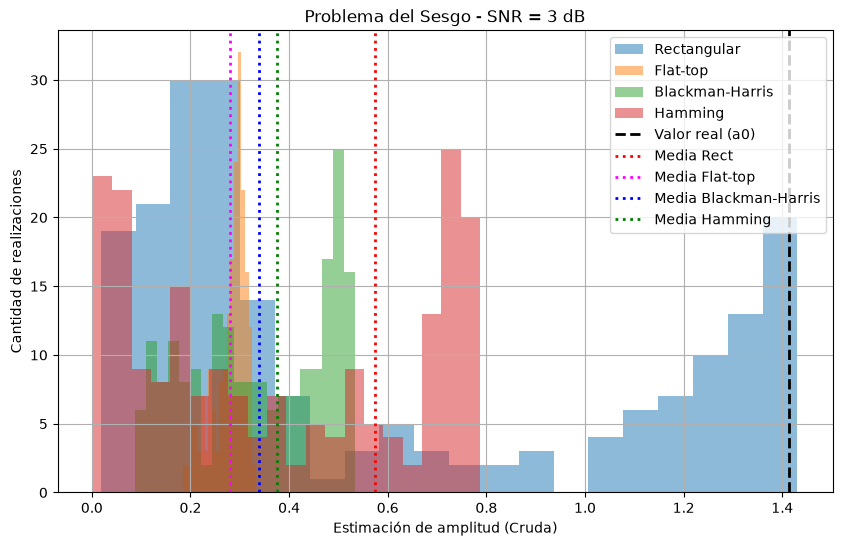

In [6]:
# -*- coding: utf-8 -*-

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# PARÁMETROS
N = 1000              
M = 200               
a0 = np.sqrt(2)       
Omega0 = np.pi / 2    
n = np.arange(N)
SNR_dB = 3          
fs = 1000

# RUIDO SEGÚN SNR
Ps = 1
Pn = Ps / (10**(SNR_dB / 10))
sigma = np.sqrt(Pn)

# GENERACIÓN (Usamos seed para que ambos bloques usen la misma señal si se corren separados)
np.random.seed(42)
x = np.zeros((M, N))
Omega1 = np.zeros(M)
for i in range(M):
    fr = np.random.uniform(-2, 2)
    Omega1[i] = Omega0 + fr * (2*np.pi/N)
    na = np.random.normal(0, sigma, N)
    x[i, :] = a0 * np.sin(Omega1[i] * n) + na

# VENTANAS Y FFT
w_rect = signal.windows.boxcar(N)
w_flattop = signal.windows.flattop(N)
w_blackmanharris = signal.windows.blackmanharris(N)
w_hamming = signal.windows.hamming(N)

mod_a_rect = np.abs(np.fft.fft(x * w_rect, axis=1)[:, :N//2])
mod_a_flat = np.abs(np.fft.fft(x * w_flattop, axis=1)[:, :N//2])
mod_a_black = np.abs(np.fft.fft(x * w_blackmanharris, axis=1)[:, :N//2])
mod_a_ham = np.abs(np.fft.fft(x * w_hamming, axis=1)[:, :N//2])

# EXTRACCIÓN CRUDA 
k0 = N // 4
est_a_rect = mod_a_rect[:, k0] * (2 / N)
est_a_flat = mod_a_flat[:, k0] * (2 / N)
est_a_black = mod_a_black[:, k0] * (2 / N)
est_a_ham = mod_a_ham[:, k0] * (2 / N)

# CÁLCULO DE MEDIAS
media_rect = np.mean(est_a_rect)
media_flat = np.mean(est_a_flat)
media_black = np.mean(est_a_black)
media_ham = np.mean(est_a_ham)

# GRAFICO
plt.figure(figsize=(10, 6))
plt.hist(est_a_rect, bins=20, alpha=0.5, label='Rectangular')
plt.hist(est_a_flat, bins=20, alpha=0.5, label='Flat-top')
plt.hist(est_a_black, bins=20, alpha=0.5, label='Blackman-Harris')
plt.hist(est_a_ham, bins=20, alpha=0.5, label='Hamming')

# LÍNEAS DE REFERENCIA
plt.axvline(a0, color='black', linestyle='--', linewidth=2, label='Valor real (a0)')
plt.axvline(media_rect, color='red', linestyle=':', linewidth=2, label='Media Rect')
plt.axvline(media_flat, color='magenta', linestyle=':', linewidth=2, label='Media Flat-top')
plt.axvline(media_black, color='blue', linestyle=':', linewidth=2, label='Media Blackman-Harris')
plt.axvline(media_ham, color='green', linestyle=':', linewidth=2, label='Media Hamming')

plt.xlabel('Estimación de amplitud (Cruda)')
plt.ylabel('Cantidad de realizaciones')
plt.title(f'Problema del Sesgo - SNR = {SNR_dB} dB')
plt.legend()
plt.grid()
plt.show()

Al analizar este primer gráfico crudo con la relación señal a ruido más baja (SNR = 3 dB), lo primero que me llamó la atención es que el comportamiento de la ventana Rectangular literalmente es un desastre: al tener más ruido compitiendo con la señal, sus estimaciones quedan desparramadas por absolutamente todas partes, abarcando casi todo el eje de amplitud.

Por otro lado, sigo sosteniendo la misma conclusión que con 10 dB: la Flat-top sigue siendo la mejor. A pesar de que el escenario ahora es mucho más ruidoso, esta ventana es la única que logra mantener sus valores bastante concentrados alrededor de su propia media. Obviamente, todas siguen teniendo un sesgo gigante (las líneas punteadas caen muy lejos de la línea negra del valor real), pero sabiendo que eso lo vamos a corregir analíticamente, este gráfico me sirve para reconfirmar de manera visual que la Flat-top es la más robusta para mantener la varianza perfecta.

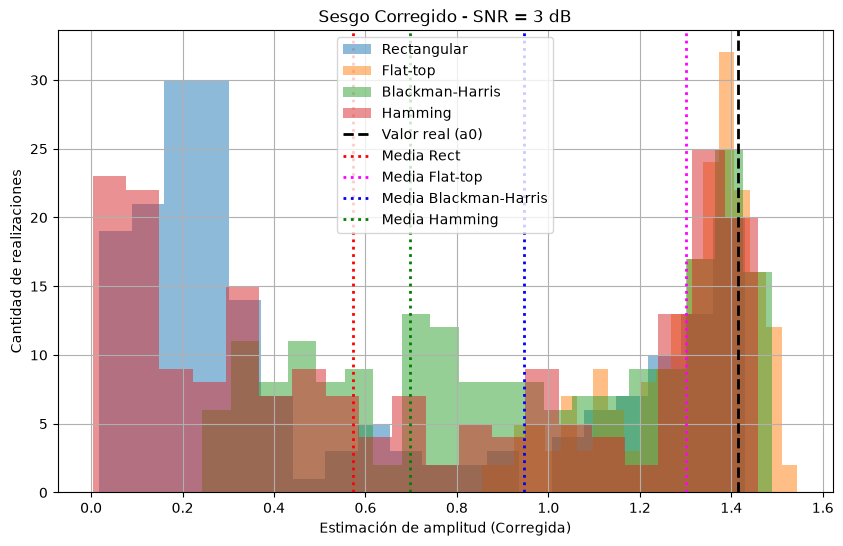

In [7]:
# -*- coding: utf-8 -*-

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# PARÁMETROS
N = 1000              
M = 200               
a0 = np.sqrt(2)       
Omega0 = np.pi / 2    
n = np.arange(N)
SNR_dB = 3          
fs = 1000

# RUIDO SEGÚN SNR
Ps = 1
Pn = Ps / (10**(SNR_dB / 10))
sigma = np.sqrt(Pn)

# GENERACIÓN (Misma semilla para mantener los mismos datos)
np.random.seed(42)
x = np.zeros((M, N))
Omega1 = np.zeros(M)
for i in range(M):
    fr = np.random.uniform(-2, 2)
    Omega1[i] = Omega0 + fr * (2*np.pi/N)
    na = np.random.normal(0, sigma, N)
    x[i, :] = a0 * np.sin(Omega1[i] * n) + na

# VENTANAS Y FFT
w_rect = signal.windows.boxcar(N)
w_flattop = signal.windows.flattop(N)
w_blackmanharris = signal.windows.blackmanharris(N)
w_hamming = signal.windows.hamming(N)

mod_a_rect = np.abs(np.fft.fft(x * w_rect, axis=1)[:, :N//2])
mod_a_flat = np.abs(np.fft.fft(x * w_flattop, axis=1)[:, :N//2])
mod_a_black = np.abs(np.fft.fft(x * w_blackmanharris, axis=1)[:, :N//2])
mod_a_ham = np.abs(np.fft.fft(x * w_hamming, axis=1)[:, :N//2])

# EXTRACCIÓN CORREGIDA (Usando la suma de cada ventana)
k0 = N // 4
est_a_rect = mod_a_rect[:, k0] * (2 / np.sum(w_rect))
est_a_flat = mod_a_flat[:, k0] * (2 / np.sum(w_flattop))
est_a_black = mod_a_black[:, k0] * (2 / np.sum(w_blackmanharris))
est_a_ham = mod_a_ham[:, k0] * (2 / np.sum(w_hamming))

# EXTRACCIÓN DE FRECUENCIA
paso_frec = 2 * np.pi / N
est_Omega_rect = np.argmax(mod_a_rect, axis=1) * paso_frec
est_Omega_flat = np.argmax(mod_a_flat, axis=1) * paso_frec
est_Omega_black = np.argmax(mod_a_black, axis=1) * paso_frec
est_Omega_ham = np.argmax(mod_a_ham, axis=1) * paso_frec

# CÁLCULOS ESTADÍSTICOS
media_rect, media_flat = np.mean(est_a_rect), np.mean(est_a_flat)
media_black, media_ham = np.mean(est_a_black), np.mean(est_a_ham)

sa_rect, va_rect = media_rect - a0, np.var(est_a_rect)
sa_flat, va_flat = media_flat - a0, np.var(est_a_flat)
sa_black, va_black = media_black - a0, np.var(est_a_black)
sa_ham, va_ham = media_ham - a0, np.var(est_a_ham)

sf_rect, vf_rect = np.mean(est_Omega_rect - Omega1), np.var(est_Omega_rect - Omega1)
sf_flat, vf_flat = np.mean(est_Omega_flat - Omega1), np.var(est_Omega_flat - Omega1)
sf_black, vf_black = np.mean(est_Omega_black - Omega1), np.var(est_Omega_black - Omega1)
sf_ham, vf_ham = np.mean(est_Omega_ham - Omega1), np.var(est_Omega_ham - Omega1)

# GRAFICO CORREGIDO
plt.figure(figsize=(10, 6))
plt.hist(est_a_rect, bins=20, alpha=0.5, label='Rectangular')
plt.hist(est_a_flat, bins=20, alpha=0.5, label='Flat-top')
plt.hist(est_a_black, bins=20, alpha=0.5, label='Blackman-Harris')
plt.hist(est_a_ham, bins=20, alpha=0.5, label='Hamming')

plt.axvline(a0, color='black', linestyle='--', linewidth=2, label='Valor real (a0)')
plt.axvline(media_rect, color='red', linestyle=':', linewidth=2, label='Media Rect')
plt.axvline(media_flat, color='magenta', linestyle=':', linewidth=2, label='Media Flat-top')
plt.axvline(media_black, color='blue', linestyle=':', linewidth=2, label='Media Blackman-Harris')
plt.axvline(media_ham, color='green', linestyle=':', linewidth=2, label='Media Hamming')

plt.xlabel('Estimación de amplitud (Corregida)')
plt.ylabel('Cantidad de realizaciones')
plt.title(f'Sesgo Corregido - SNR = {SNR_dB} dB')
plt.legend()
plt.grid()
plt.show()


Con la corrección aplicada, llegamos a la misma conclusión que con 10 dB, pero en un escenario más extremo. Al tener tanto ruido de fondo, el problema de la pérdida de ganancia cuando la frecuencia no cae exacta en un bin es mucho mas castastrofico. Podemos ver que ventanas como la Rectangular o la Hamming, por más que las hayamos corregido, quedan lejísimos de la línea negra del valor real y sus datos siguen totalmente dispersos.

Para no repetir exactamente el mismo análisis anterior que hice con 10 dB, lo que más destaco de este gráfico con SNR de 3 dB es cómo el ruido ensanchó absolutamente todas las distribuciones. La ventana Flat-top vuelve a ser la única que logra arrimar su media al 1,41, pero si la comparamos con el de 10 dB, se nota muchísimo el impacto del ruido proque ya no esta un pico tan finito y perfecto, sino que ahora tiene un "desparramo" un poco más notable. De todas formas, al ver lo mal que estan las demás, este gráfico nos termina de confirmar que la Flat-top es nuestra única opción viable para estimar amplitud cuando la señal está tan tapada por el ruido.

In [9]:
# -*- coding: utf-8 -*-

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# PARÁMETROS
N = 1000              
M = 200               
a0 = np.sqrt(2)       
Omega0 = np.pi / 2    
n = np.arange(N)
SNR_dB = 3          
fs = 1000

# RUIDO SEGÚN SNR
Ps = 1
Pn = Ps / (10**(SNR_dB / 10))
sigma = np.sqrt(Pn)

# GENERACIÓN (Misma semilla para mantener los mismos datos)
np.random.seed(42)
x = np.zeros((M, N))
Omega1 = np.zeros(M)
for i in range(M):
    fr = np.random.uniform(-2, 2)
    Omega1[i] = Omega0 + fr * (2*np.pi/N)
    na = np.random.normal(0, sigma, N)
    x[i, :] = a0 * np.sin(Omega1[i] * n) + na

# VENTANAS Y FFT
w_rect = signal.windows.boxcar(N)
w_flattop = signal.windows.flattop(N)
w_blackmanharris = signal.windows.blackmanharris(N)
w_hamming = signal.windows.hamming(N)

mod_a_rect = np.abs(np.fft.fft(x * w_rect, axis=1)[:, :N//2])
mod_a_flat = np.abs(np.fft.fft(x * w_flattop, axis=1)[:, :N//2])
mod_a_black = np.abs(np.fft.fft(x * w_blackmanharris, axis=1)[:, :N//2])
mod_a_ham = np.abs(np.fft.fft(x * w_hamming, axis=1)[:, :N//2])

# EXTRACCIÓN CORREGIDA (Usando la suma de cada ventana)
k0 = N // 4
est_a_rect = mod_a_rect[:, k0] * (2 / np.sum(w_rect))
est_a_flat = mod_a_flat[:, k0] * (2 / np.sum(w_flattop))
est_a_black = mod_a_black[:, k0] * (2 / np.sum(w_blackmanharris))
est_a_ham = mod_a_ham[:, k0] * (2 / np.sum(w_hamming))

# EXTRACCIÓN DE FRECUENCIA
paso_frec = 2 * np.pi / N
est_Omega_rect = np.argmax(mod_a_rect, axis=1) * paso_frec
est_Omega_flat = np.argmax(mod_a_flat, axis=1) * paso_frec
est_Omega_black = np.argmax(mod_a_black, axis=1) * paso_frec
est_Omega_ham = np.argmax(mod_a_ham, axis=1) * paso_frec

# CÁLCULOS ESTADÍSTICOS
media_rect, media_flat = np.mean(est_a_rect), np.mean(est_a_flat)
media_black, media_ham = np.mean(est_a_black), np.mean(est_a_ham)

sa_rect, va_rect = media_rect - a0, np.var(est_a_rect)
sa_flat, va_flat = media_flat - a0, np.var(est_a_flat)
sa_black, va_black = media_black - a0, np.var(est_a_black)
sa_ham, va_ham = media_ham - a0, np.var(est_a_ham)

sf_rect, vf_rect = np.mean(est_Omega_rect - Omega1), np.var(est_Omega_rect - Omega1)
sf_flat, vf_flat = np.mean(est_Omega_flat - Omega1), np.var(est_Omega_flat - Omega1)
sf_black, vf_black = np.mean(est_Omega_black - Omega1), np.var(est_Omega_black - Omega1)
sf_ham, vf_ham = np.mean(est_Omega_ham - Omega1), np.var(est_Omega_ham - Omega1)


# TABLAS
print(f"\n--- RESULTADOS PARA SNR = {SNR_dB} dB ---")
print("\nESTIMACIÓN DE AMPLITUD")
print(f"{'Ventana':<15} | {'Sesgo (sa)':<12} | {'Varianza (va)':<12}")
print("-" * 45)
print(f"{'Rectangular':<15} | {sa_rect:>12.4f} | {va_rect:>12.4f}")
print(f"{'Flat-top':<15} | {sa_flat:>12.4f} | {va_flat:>12.4f}")
print(f"{'Blackman':<15} | {sa_black:>12.4f} | {va_black:>12.4f}")
print(f"{'Hamming':<15} | {sa_ham:>12.4f} | {va_ham:>12.4f}")

print("\nESTIMACIÓN DE FRECUENCIA")
print(f"{'Ventana':<15} | {'Sesgo (sf)':<12} | {'Varianza (vf)':<12}")
print("-" * 45)
print(f"{'Rectangular':<15} | {sf_rect:>12.4e} | {vf_rect:>12.4e}")
print(f"{'Flat-top':<15} | {sf_flat:>12.4e} | {sf_flat:>12.4e}")
print(f"{'Blackman':<15} | {sf_black:>12.4e} | {vf_black:>12.4e}")
print(f"{'Hamming':<15} | {sf_ham:>12.4e} | {vf_ham:>12.4e}")


--- RESULTADOS PARA SNR = 3 dB ---

ESTIMACIÓN DE AMPLITUD
Ventana         | Sesgo (sa)   | Varianza (va)
---------------------------------------------
Rectangular     |      -0.8406 |       0.2444
Flat-top        |      -0.1140 |       0.0244
Blackman        |      -0.4668 |       0.1463
Hamming         |      -0.7176 |       0.2679

ESTIMACIÓN DE FRECUENCIA
Ventana         | Sesgo (sf)   | Varianza (vf)
---------------------------------------------
Rectangular     |   1.4898e-04 |   2.8850e-06
Flat-top        |   5.4734e-05 |   5.4734e-05
Blackman        |   1.4898e-04 |   2.9172e-06
Hamming         |   1.4898e-04 |   2.8850e-06


**Análisis de la Estimación de Amplitud**
La Flat-top es la mejor. Consigue la menor varianza (0.0244) y el menor sesgo (-0.1140).Si comparamos esta varianza con la que nos dio en 10 dB (que era 0.0217), notamos que efectivamente subió un poquito. Esto tiene todo el sentido del mundo porque ahora tenemos mucho más ruido ensuciando la señal.
Las ventanas Rectangular y Hamming siguen teniendo un sesgo gigante (-0.84 y -0.71) y una varianza altísima (0.24 y 0.26), demostrando que no sirven para medir amplitud cuando la frecuencia cae fuera del centro del bin.
**Análisis de la Estimación de Frecuencia**
La Flat-top, que era excelente para la amplitud, pasa a ser la peor opción en frecuencia: tiene la varianza más alta (5.47e-05) por culpa de tener ese lóbulo principal tan ancho y chato.En cambio, la Rectangular y la Hamming logran las varianzas más bajas (en el orden de 2.88e-06). Al tener un lóbulo principal tan angosto, generan un pico muy agudo que el ruido casi no logra mover, dándonos muchísima más precisión para detectar la frecuencia.

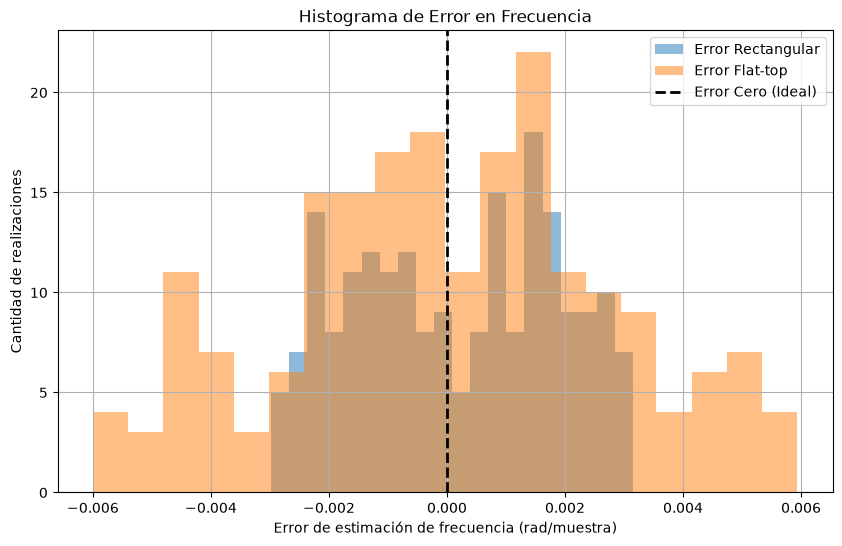

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# PARÁMETROS
N = 1000              
M = 200               
a0 = np.sqrt(2)       
Omega0 = np.pi / 2    
n = np.arange(N)
SNR_dB = 3          
fs = 1000

# RUIDO SEGÚN SNR
Ps = 1
Pn = Ps / (10**(SNR_dB / 10))
sigma = np.sqrt(Pn)

# GENERACIÓN (Misma semilla para mantener los mismos datos)
np.random.seed(42)
x = np.zeros((M, N))
Omega1 = np.zeros(M)
for i in range(M):
    fr = np.random.uniform(-2, 2)
    Omega1[i] = Omega0 + fr * (2*np.pi/N)
    na = np.random.normal(0, sigma, N)
    x[i, :] = a0 * np.sin(Omega1[i] * n) + na

# VENTANAS Y FFT
w_rect = signal.windows.boxcar(N)
w_flattop = signal.windows.flattop(N)
w_blackmanharris = signal.windows.blackmanharris(N)
w_hamming = signal.windows.hamming(N)

mod_a_rect = np.abs(np.fft.fft(x * w_rect, axis=1)[:, :N//2])
mod_a_flat = np.abs(np.fft.fft(x * w_flattop, axis=1)[:, :N//2])
mod_a_black = np.abs(np.fft.fft(x * w_blackmanharris, axis=1)[:, :N//2])
mod_a_ham = np.abs(np.fft.fft(x * w_hamming, axis=1)[:, :N//2])

# EXTRACCIÓN CORREGIDA (Usando la suma de cada ventana)
k0 = N // 4
est_a_rect = mod_a_rect[:, k0] * (2 / np.sum(w_rect))
est_a_flat = mod_a_flat[:, k0] * (2 / np.sum(w_flattop))
est_a_black = mod_a_black[:, k0] * (2 / np.sum(w_blackmanharris))
est_a_ham = mod_a_ham[:, k0] * (2 / np.sum(w_hamming))

# EXTRACCIÓN DE FRECUENCIA
paso_frec = 2 * np.pi / N
est_Omega_rect = np.argmax(mod_a_rect, axis=1) * paso_frec
est_Omega_flat = np.argmax(mod_a_flat, axis=1) * paso_frec
est_Omega_black = np.argmax(mod_a_black, axis=1) * paso_frec
est_Omega_ham = np.argmax(mod_a_ham, axis=1) * paso_frec

# CÁLCULOS ESTADÍSTICOS
media_rect, media_flat = np.mean(est_a_rect), np.mean(est_a_flat)
media_black, media_ham = np.mean(est_a_black), np.mean(est_a_ham)

sa_rect, va_rect = media_rect - a0, np.var(est_a_rect)
sa_flat, va_flat = media_flat - a0, np.var(est_a_flat)
sa_black, va_black = media_black - a0, np.var(est_a_black)
sa_ham, va_ham = media_ham - a0, np.var(est_a_ham)

sf_rect, vf_rect = np.mean(est_Omega_rect - Omega1), np.var(est_Omega_rect - Omega1)
sf_flat, vf_flat = np.mean(est_Omega_flat - Omega1), np.var(est_Omega_flat - Omega1)
sf_black, vf_black = np.mean(est_Omega_black - Omega1), np.var(est_Omega_black - Omega1)
sf_ham, vf_ham = np.mean(est_Omega_ham - Omega1), np.var(est_Omega_ham - Omega1)
plt.figure(figsize=(10, 6))
# Graficamos la diferencia entre lo estimado y lo real
plt.hist(est_Omega_rect - Omega1, bins=20, alpha=0.5, label='Error Rectangular')
plt.hist(est_Omega_flat - Omega1, bins=20, alpha=0.5, label='Error Flat-top')

plt.axvline(0, color='black', linestyle='--', linewidth=2, label='Error Cero (Ideal)')
plt.xlabel('Error de estimación de frecuencia (rad/muestra)')
plt.ylabel('Cantidad de realizaciones')
plt.title('Histograma de Error en Frecuencia')
plt.legend()
plt.grid()
plt.show()

Para analizar visualmente qué pasaba con la frecuencia, me di cuenta de que no servía graficar las estimaciones directamente. Como a cada realización le sumamos un corrimiento aleatorio, la frecuencia real cambia todo el tiempo. Por eso, decidí graficar el error de estimación (la diferencia entre la frecuencia calculada y la real).Al ver el gráfico, se ve clarísimo cómo se invierten los roles respecto al cálculo de amplitud. La ventana Rectangular, que antes era un desastre, acá forma un pico angosto y súper concentrado alrededor del cero. Esto ocurre porque su lóbulo principal en el espectro es muy finito, lo que nos da una precisión excelente para detectar la frecuencia. Por el contrario, la Flat-top muestra un 'desparramo' mucho mayor. Ese mismo lóbulo ancho y de techo plano que nos garantizaba una amplitud estable, acá le juega en contra, frente al ruido, el pico máximo baila entre varios bines, aumentando la incertidumbre y disparando la varianza de nuestra estimación.

BONUS

**Analice el efecto del zero-padding para el estimador Ω^1**


Para analizar el efecto del zero-padding, lo que hacemos es agregarle un montón de ceros al final de nuestra señal original antes de calcularle la FFT.
Agregar los ceros no nos da "nueva información" de la señal, pero lo que sí hace es calcular muchos más "puntitos" intermedios en el espectro (es decir, achica la separación entre los bines). Como nuestro estimador de frecuencia funciona buscando en qué bin cae el pico máximo, al tener el espectro mucho más subdividido, la posición de ese pico va a coincidir con mucha más exactitud con la frecuencia real. Básicamente, el zero-padding nos permite afinar la puntería, reduciendo drásticamente la varianza del estimador de frecuencia.


--- BONUS: ZERO PADDING (SNR = 10 dB) ---
Rectangular | Sin : 2.8850e-06 | Con : 3.6879e-08
Flat-top    | Sin : 4.8757e-06 | Con : 6.0025e-06


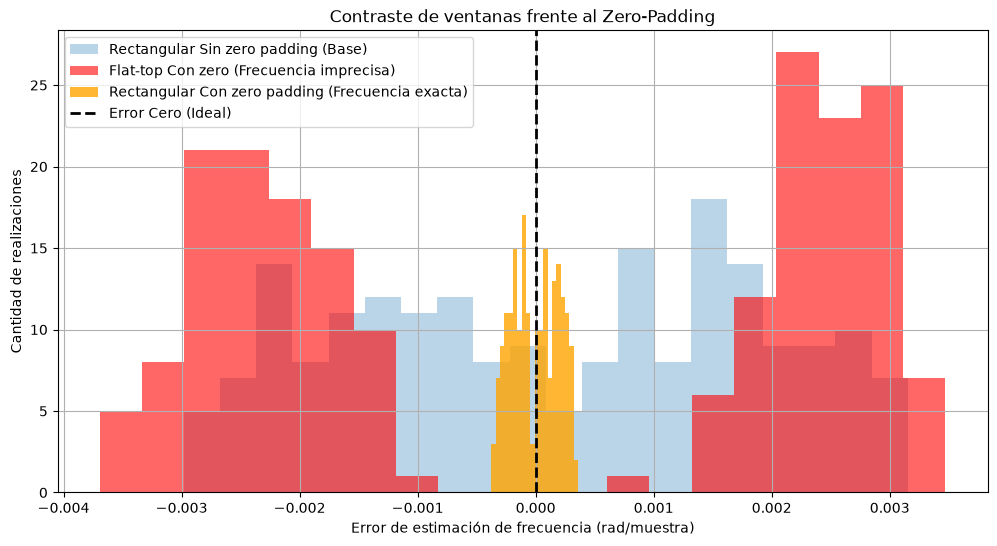

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

N = 1000
M = 200
a0 = np.sqrt(2)
Omega0 = np.pi / 2
n = np.arange(N)
SNR_dB = 10          
fs = 1000

Ps = 1
Pn = Ps / (10**(SNR_dB / 10))
sigma = np.sqrt(Pn)

np.random.seed(42)
x = np.zeros((M, N))
Omega1 = np.zeros(M)
for i in range(M):
    fr = np.random.uniform(-2, 2)
    Omega1[i] = Omega0 + fr * (2*np.pi/N)
    na = np.random.normal(0, sigma, N)
    x[i, :] = a0 * np.sin(Omega1[i] * n) + na

# VENTANAS
w_rect = signal.windows.boxcar(N)
w_flattop = signal.windows.flattop(N)

# FFT NORMAL (Sin Zero-padding)
paso_frec = 2 * np.pi / N

mod_a_rect = np.abs(np.fft.fft(x * w_rect, axis=1)[:, :N//2])
est_Omega_rect = np.argmax(mod_a_rect, axis=1) * paso_frec
vf_rect = np.var(est_Omega_rect - Omega1)

mod_a_flat = np.abs(np.fft.fft(x * w_flattop, axis=1)[:, :N//2])
est_Omega_flat = np.argmax(mod_a_flat, axis=1) * paso_frec
vf_flat = np.var(est_Omega_flat - Omega1)

# FFT CON ZERO PADDING
factor_pad = 10
N_pad = N * factor_pad
paso_frec_pad = 2 * np.pi / N_pad

mod_a_rect_pad = np.abs(np.fft.fft(x * w_rect, n=N_pad, axis=1)[:, :N_pad//2])
est_Omega_rect_pad = np.argmax(mod_a_rect_pad, axis=1) * paso_frec_pad
vf_rect_pad = np.var(est_Omega_rect_pad - Omega1)

mod_a_flat_pad = np.abs(np.fft.fft(x * w_flattop, n=N_pad, axis=1)[:, :N_pad//2])
est_Omega_flat_pad = np.argmax(mod_a_flat_pad, axis=1) * paso_frec_pad
vf_flat_pad = np.var(est_Omega_flat_pad - Omega1)

print(f"\n--- BONUS: ZERO PADDING (SNR = {SNR_dB} dB) ---")
print(f"Rectangular | Sin : {vf_rect:.4e} | Con : {vf_rect_pad:.4e}")
print(f"Flat-top    | Sin : {vf_flat:.4e} | Con : {vf_flat_pad:.4e}")

# GRÁFICO
plt.figure(figsize=(12, 6))
plt.hist(est_Omega_rect - Omega1, bins=20, alpha=0.3, label='Rectangular Sin zero padding (Base)')
plt.hist(est_Omega_flat_pad - Omega1, bins=20, alpha=0.6, color='red', label='Flat-top Con zero (Frecuencia imprecisa)')
plt.hist(est_Omega_rect_pad - Omega1, bins=20, alpha=0.8, color='orange', label='Rectangular Con zero padding (Frecuencia exacta)')

plt.axvline(0, color='black', linestyle='--', linewidth=2, label='Error Cero (Ideal)')
plt.xlabel('Error de estimación de frecuencia (rad/muestra)')
plt.ylabel('Cantidad de realizaciones')
plt.title('Contraste de ventanas frente al Zero-Padding')
plt.legend()
plt.grid()
plt.show()

Como dije arriba agregar ceros no suma información real a la señal, pero lo que se logra con esto es obligar a la función a calcular muchísimos más puntos intermedios en el espectro. Es decir, achicamos un montón la separación entre los bines. En el gráfico que armamos se ve clarísimo el impacto. Las barras azules muestran el error original que teníamos con 1000 muestras, donde los resultados nos daban re desparramados porque, al estar los bines tan separados, el código siempre terminaba redondeando al más cercano y le erraba bastante a la frecuencia exacta. En cambio, la parte naranja es la estimación aplicando zero-padding para llegar a 10000 muestras. Al tener el espectro tan subdividido, logramos afinar. Se nota cómo las barras naranjas abandonan todo ese desparramo azul y se amontonan formando un pico súper finito que queda clavado en la línea negra del error cero. Básicamente, confirmamos que al agregar los ceros bajamos la varianza drásticamente y le apuntamos a la frecuencia con muchísima más exactitud.

Ninguna ventana sirve para todo a la vez.
Cuando queríamos estimar la amplitud en los primeros gráficos, la ventana Rectangular nos daba re mal.En cambio, la Flat-top era la mejor opción porque, al tener el techo chato, el corrimiento no afecta y la amplitud se mantiene estable.

Pero para la frecuencia, como vemos en el bonus, los roles se invierten por completo. Ese mismo pico tan finito y filoso de la ventana Rectangular ahora es nuestra mayor ventaja, porque nos esta marcando la posición exacta de la frecuencia. Y al sumarle el zero-padding, le doy muchísimos más puntos de lectura a este pico, haciendo que la precisión sea muy buena. La Flat-top acá no es lo mejor: al tener una cima tan ancha y plana, cuando le sumás un poco de ruido, el código duda y le cuesta un montón identificar cuál de todos esos bines chatos es el centro real.

En resumen, comprobamos en la práctica que siempre hay que sacrificar algo: usamos la Rectangular (y la ayudamos con zero-padding) si nuestra prioridad es tener la frecuencia exacta, y elegimos la Flat-top si lo que nos importa es no perder ganancia y medir la amplitud sin errores.
Podemos decir entonces que agregar el zero padding a la ventana que ya sabíamos que era la mejor para estimar frecuencia, simplemente nos ayuda a encontrar la frecuencia perfecta, ya que nos deja ver el pico más claro.

**Proponga estimadores alternativos para frecuencia y amplitud de la senoidal y repita el experimento.**

Para este último bonus, me puse a leer más adelante en el mismo capítulo 14 del Holton para ver qué otras opciones existen para estimar espectros con ruido. Ahí explican que los que armamos nosotros son métodos "no paramétricos" básicos, pero que existen versiones mejoradas para bajar la varianza, como el método de Bartlett o el método de Welch, que básicamente dividen la señal y promedian los resultados. También vi que existe toda otra rama de estimadores "paramétricos" (como los modelos ARMA o el algoritmo de Levinson-Durbin) que el libro plantea justamente para problemas como el nuestro de una senoidal con ruido.  Pero, siendo 100% sincera, la verdad es que la implementación me pareció muy complicada. No sé muy bien cómo encararlo a nivel código ni cómo programar toda esa matemática de matrices. Por eso, preferí dejar las ideas planteadas conceptualmente para mostrar las opciones que encontré leyendo el Holton, pero decidí no meter ese código para no hacer lío y quedarme con los estimadores clásicos que ya analicé.